In [1]:
from gaussian_beam import *
from adjointold import *
from plot import *
import matplotlib.pyplot as plt

NameError: name 'ipython' is not defined

In [ ]:
path = "base/delta_f_targ_0.05_f_init_0.045_ell_0_wl_1e-06_f_num_25_conic_-1_nr_1000_r_maxf_5_nzf_501_dz_0.02_steps_5000_lr_5e-11_delta_1_tol_0.01_sg_0_order_0.txt"
params = initialize_variables_from_file(path)
dirname = (path.split("/")[-1])[:-4]
path = "runs/" + dirname

In [ ]:
f = params["f_targ"]  # focal length of lens
ell = 0  # order of Bessel J function
mir_i = params["f_init"]  # initial mirror focal length
conic = params["conic"]

# Beam Parameters
wl = params["wl"]  # wavelength
k0 = 2 * np.pi / wl  # k=2*pi/wavelength
fn = params["f_num"]  # f#
w0 = f / (2 * fn)  # initial spot size
rmax = params["r_maxf"] * w0  # the max value of r
nr = params["nr"]  # number of points in r
zR = np.pi * w0**2 / wl  # Initial rayleigh length
wR = 2 / np.pi * fn * wl  # Diffraction limited spot size

# Distance parameters
dz = params["dz"]
nzf = params["nzf"]
zF = np.linspace(f - dz, f + dz, nzf)
fl = len(zF) // 2  # focal length index

# Guess parameters
OoM = math.floor(math.log(w0**2, 10))  # order of magnitude of w0^2
w_guess = 10**OoM  # guess for the spot size
steps = params["steps"]  # max number of steps algorithm is allowed
lr = params["lr"]  # learning rate
tol = params["tol"]  # tolerance
delta = params["delta"]  # weighting function in r

In [ ]:
# Hankel
[r, k] = DHTarrays(nr, rmax, ell)
[T_R2K, T_K2R] = DHTtransformMatrix(nr, rmax, ell)

In [ ]:
phi_I = 1j * np.exp(-((r / w0) ** 2))
zm_t = create_starting_optic(r, 2 * f)  # target mirror
ftf_t = forward_propagation(
    w0, r, k, phi_I, T_R2K, T_K2R, zF, zm_t
)  # Target profile defined using target mirror

zm_r = create_starting_optic(r, 2 * mir_i, k=conic)  # initial mirror
ftf_r = forward_propagation(w0, r, k, phi_I, T_R2K, T_K2R, zF, zm_r)


In [ ]:
# Adjoint
psi_hat = adjoint(
    r, 2 * wR, k, k0, zF, f - dz, f + dz, ftf_r, ftf_t, T_R2K, T_K2R, delta
)
psi = T_K2R @ psi_hat
grad = np.real(gradient(k0, phi_I, psi, zm_r))

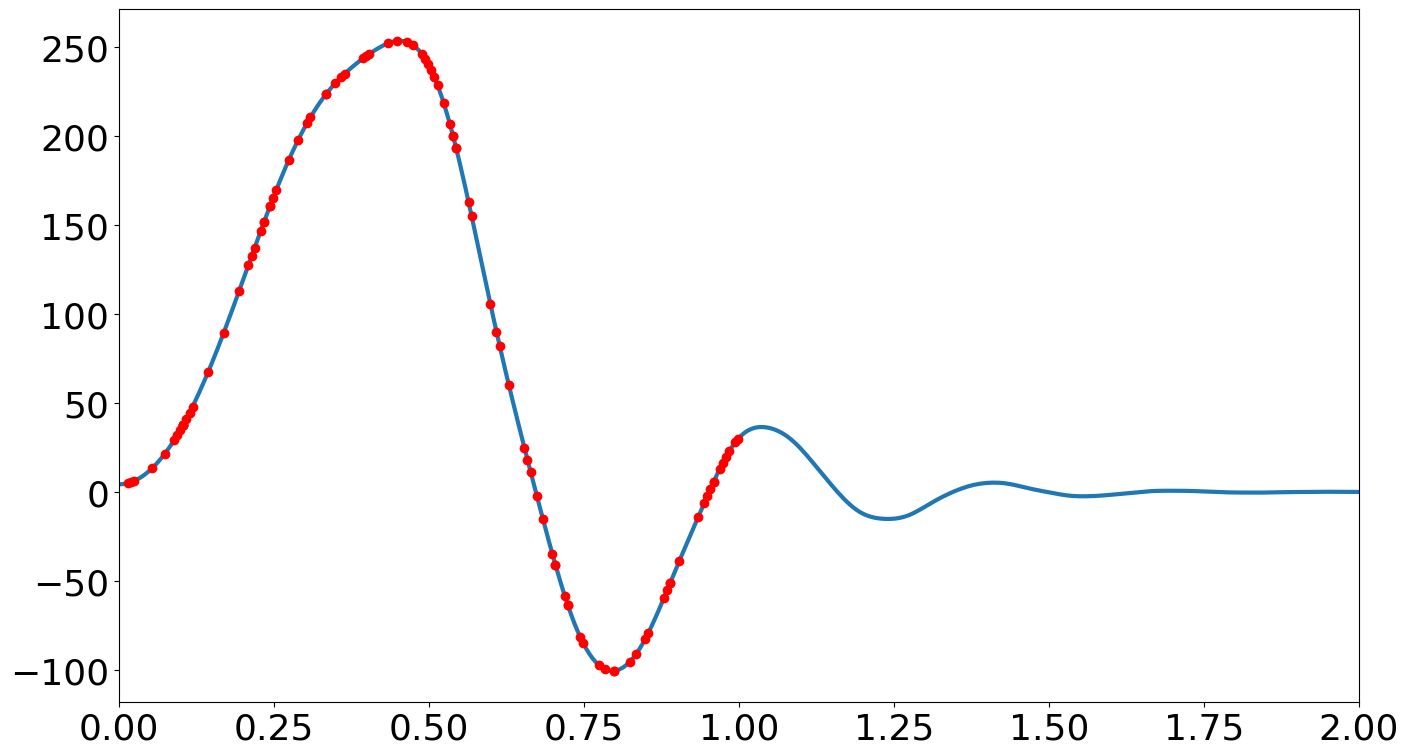

In [ ]:
plt.plot(r/w0, grad)
plt.xlim(0,2)

#choose 10 random points on grad on limit and plot them
indices = np.random.choice(len(grad)//5, 100)
for i in indices:
    plt.plot(r[i]/w0, grad[i], 'ro')
plt.savefig('grad.png')

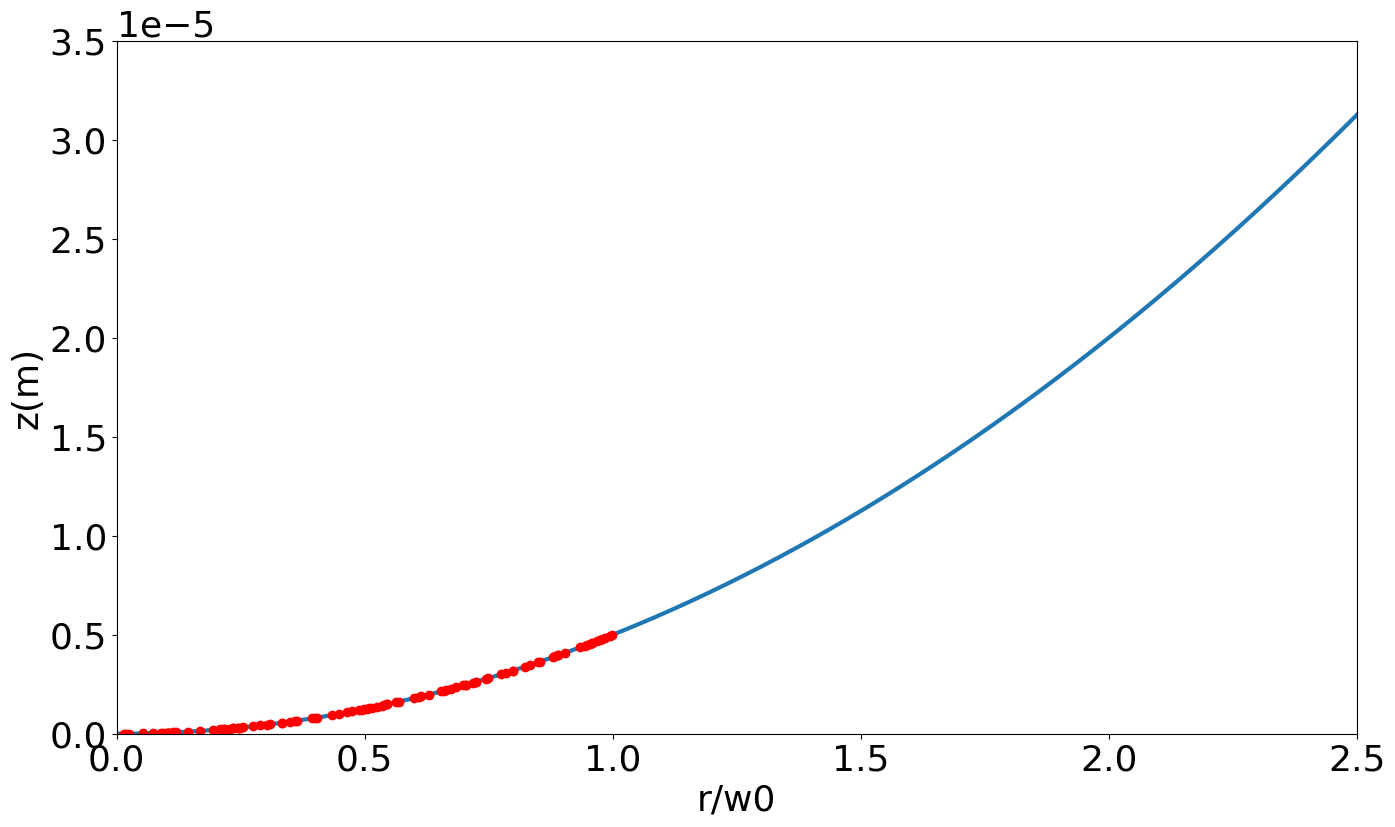

In [ ]:
plt.plot(r/w0, zm_t)
for i in indices:
    plt.plot(r[i]/w0, zm_t[i], 'ro')
plt.xlim(0,2.5)
plt.ylim(0,3.5e-5)
plt.xlabel('r/w0')
plt.ylabel('z(m)')
# sci notation y axis
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

plt.savefig('sample_zm')
plt.show()

In [ ]:
def zern_pols(rho):
    pols = [
        np.ones_like(rho),  # 1st polynomial is constant
        np.sqrt(3) * (2 * rho**2 - 1),  # 2nd polynomial
        np.sqrt(5) * (6 * rho**4 - 6 * rho**2 + 1)  # 3rd polynomial
    ]
    return np.column_stack(pols)  

In [ ]:
data_r=r[indices]/w0
data_grad=grad[indices]
data_mirror=zm_t[indices]
A=zern_pols(data_r)

In [ ]:
print(A)

[[ 1.         -1.34599259  0.90750377]
 [ 1.         -1.5175947   1.45690303]
 [ 1.         -0.25078897 -1.04771512]
 [ 1.         -1.56620303  1.62449436]
 [ 1.         -1.31051111  0.8021216 ]
 [ 1.          0.21099012 -1.06826266]
 [ 1.         -1.69474216  2.09312843]
 [ 1.         -0.03984964 -1.11625856]
 [ 1.          1.00553261  0.01240552]
 [ 1.         -1.68317494  2.04944335]
 [ 1.         -1.07998981  0.18601625]
 [ 1.         -1.69105971  2.07918873]
 [ 1.         -1.34599259  0.90750377]
 [ 1.         -0.15877107 -1.0898503 ]
 [ 1.          0.47915904 -0.86134078]
 [ 1.         -0.01554547 -1.1177638 ]
 [ 1.         -1.18097556  0.44129166]
 [ 1.         -0.22804443 -1.05989145]
 [ 1.          1.45375162  1.2448121 ]
 [ 1.          0.3968888  -0.94192047]
 [ 1.         -0.70732599 -0.55867035]
 [ 1.          1.38764084  1.03479311]
 [ 1.         -1.52612932  1.48594622]
 [ 1.         -1.69474216  2.09312843]
 [ 1.          1.6220612   1.82360571]
 [ 1.         -0.72608481

In [ ]:
print(A.T @ A)
#print the determinant
print(np.linalg.det(A.T @ A))

[[100.         -51.07928229  50.63679383]
 [-51.07928229 145.29092527 -71.11596873]
 [ 50.63679383 -71.11596873 165.64360382]]
1464066.9375017406


In [ ]:
#calculate (A^T*A)^-1
ATA_inv=np.linalg.inv(A.T @ A)
print(ATA_inv)

[[ 0.01298372  0.00331943 -0.00254395]
 [ 0.00331943  0.00956259  0.00309078]
 [-0.00254395  0.00309078  0.0081417 ]]


In [ ]:
x=ATA_inv @ A.T @ data_grad
print(x)

[ 51.32683599 -61.77301154  -8.04253142]


In [ ]:
w=ATA_inv @ A.T @ data_mirror
print(w)

[2.50000000e-06 1.44337567e-06 3.97046694e-23]


In [ ]:
print(1/2/np.sqrt(3))

0.2886751345948129


In [ ]:
def zernike_fit(rho, x):
    pols = zern_pols(rho)
    return np.dot(pols, x)

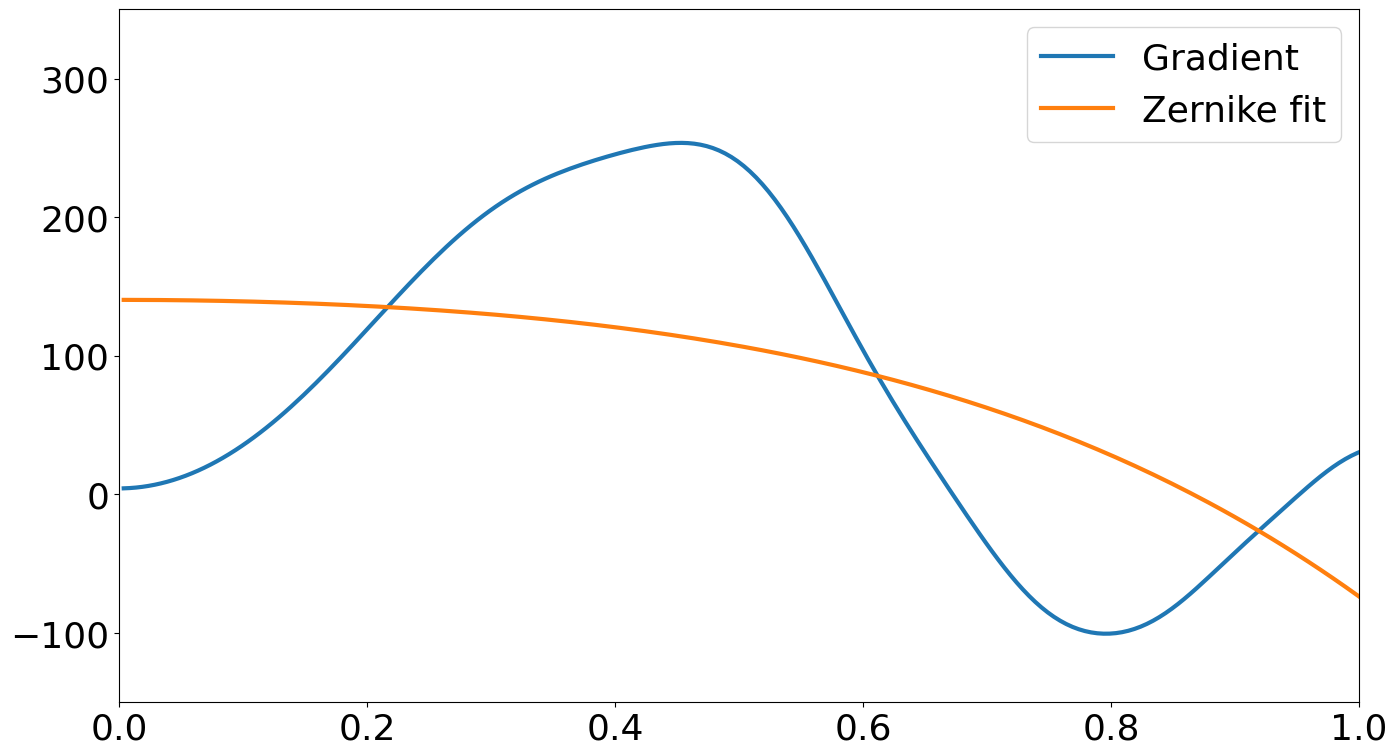

In [ ]:
#plot the gradient vs the zernike polynomials
plt.plot(r/w0, grad , label='Gradient')
plt.plot(r/w0, zernike_fit(r/w0, x), label='Zernike fit')
plt.xlim(0,1)
plt.ylim(-150,350)
plt.legend()

plt.savefig('zernike_fit_grad.png')
plt.show()

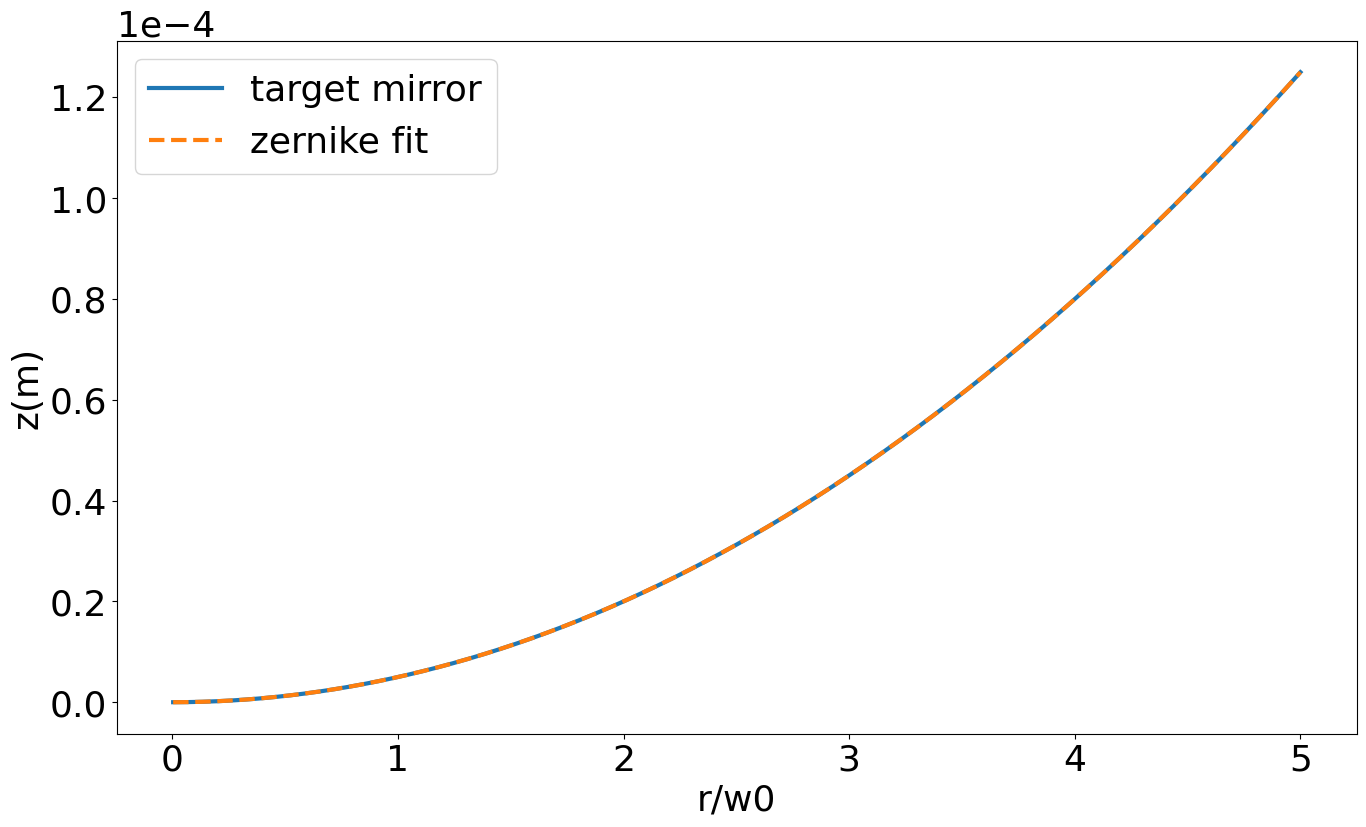

In [ ]:
plt.plot(r/w0, zm_t, label='target mirror')
plt.plot(r/w0, zernike_fit(r/w0, w),linestyle='dashed',label='zernike fit')
# plt.xlim(0,0.002)
# plt.ylim(-150,350)
plt.legend()
plt.xlabel('r/w0')
plt.ylabel('z(m)')
# sci notation y axis
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

plt.savefig('zernike_fit_mirror.png')